## Tahap 1: Pemuatan Data & Inspeksi Awal
Pada tahap ini, dataset E-Commerce (format CSV) dimuat ke dalam DataFrame. Dilakukan inspeksi awal untuk melihat dimensi data (`shape`), tipe data dan jumlah *missing value* (`info()`), serta ringkasan statistik deskriptif (`describe()`).

In [1]:
# ============================================================
# CELL 1 — Setup & Load
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, re
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA_PATH = '/content/data/case3_ecommerce_transactions.csv'
df = pd.read_csv(DATA_PATH)

print('Shape awal :', df.shape)
print('Kolom      :', list(df.columns))
df.head()

print("\n=== DESCRIBE DATA MENTAH ===")
display(df.describe())

Shape awal : (10000, 14)
Kolom      : ['transaction_id', 'user_id', 'product_id', 'kategori_produk', 'nama_produk', 'harga_idr', 'kuantitas', 'diskon_pct', 'rating_pembeli', 'sentimen_ulasan', 'tanggal_pembelian', 'metode_pembayaran', 'kota_pembeli', 'status_retur']

=== DESCRIBE DATA MENTAH ===


,harga_idr,kuantitas,diskon_pct,rating_pembeli
count,9.702000e+03,9805.000000,10000.000000,9463.000000
mean,2.513745e+06,3.011117,13.204500,2.997633
std,1.434086e+06,1.418814,10.544657,1.150633
min,1.002500e+04,1.000000,0.000000,1.000000
25%,1.262930e+06,2.000000,5.000000,2.000000
50%,2.499292e+06,3.000000,15.000000,3.000000
75%,3.755658e+06,4.000000,20.000000,4.000000
max,4.999941e+06,5.000000,30.000000,5.000000


## Tahap 2: Audit Kualitas Data

Pada tahap ini, dilakukan audit untuk mencari masalah pada data mentah sebelum dibersihkan.
Audit mencakup:
- Pengecekan tipe data dan jumlah *missing value* melalui `df.info()`.
- Perhitungan persentase *missing value* per kolom.
- Pengecekan data duplikat berdasarkan `transaction_id` dan baris penuh.
- Pengecekan nilai unik (termasuk potensi *typo* atau inkonsistensi) pada kolom kategorikal seperti `sentimen_ulasan` dan `kota_pembeli`.

In [2]:
# ============================================================
# CELL 2 — Audit Kualitas Data (mencari masalah)
# ============================================================
print('===== INFO =====')
df.info()

print('\n===== RINGKASAN MISSING VALUE =====')
miss = pd.DataFrame({
    'missing' : df.isna().sum(),
    'persen'  : (df.isna().mean()*100).round(2)
}).sort_values('missing', ascending=False)
print(miss[miss['missing'] > 0])

print('\n===== DUPLIKAT =====')
print('Jumlah duplikat transaction_id :', df['transaction_id'].duplicated().sum())
print('Jumlah duplikat baris penuh    :', df.duplicated().sum())

print('\n===== NILAI UNIK KATEGORIKAL =====')
for c in ['kategori_produk','metode_pembayaran','kota_pembeli',
          'status_retur','sentimen_ulasan']:
    print(f'\n[{c}]')
    print(df[c].value_counts(dropna=False).head(15))

===== INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     10000 non-null  object 
 1   user_id            9911 non-null   object 
 2   product_id         10000 non-null  object 
 3   kategori_produk    10000 non-null  object 
 4   nama_produk        9804 non-null   object 
 5   harga_idr          9702 non-null   float64
 6   kuantitas          9805 non-null   float64
 7   diskon_pct         10000 non-null  int64  
 8   rating_pembeli     9463 non-null   float64
 9   sentimen_ulasan    9601 non-null   object 
 10  tanggal_pembelian  9813 non-null   object 
 11  metode_pembayaran  10000 non-null  object 
 12  kota_pembeli       9724 non-null   object 
 13  status_retur       10000 non-null  object 
dtypes: float64(3), int64(1), object(10)
memory usage: 1.1+ MB

===== RINGKASAN MISSING VALUE =====
       

## Tahap 3: Pembersihan Data (Cleaning)

Pada tahap ini, data dibersihkan secara berurutan:
1. **Deduplikasi:** Menghapus baris ganda berdasarkan `transaction_id` untuk memastikan setiap transaksi unik.
2. **Konversi Tipe Data:** Mengubah format tanggal menjadi `datetime` dan memastikan kolom numerik terbaca dengan benar.
3. **Normalisasi Sentimen:** Menyeragamkan penulisan ulasan (misal `Neg@tif` atau `POSITIF` menjadi `Negatif`/`Positif`).
4. **Penanganan Missing Value:** Baris yang tidak memiliki `rating_pembeli` atau `tanggal_pembelian` dihapus untuk mencegah *data leakage* pada saat pemodelan. Missing value pada kolom kategorikal diisi dengan label yang sesuai.
5. **Penanganan Outlier:** Nilai ekstrem pada `harga_idr` dan `kuantitas` di-*clip* (dibatasi) menggunakan metode IQR agar tidak mendistorsi analisis.

In [3]:
# ============================================================
# CELL 3 — Cleaning & Normalisasi (FIXED VERSION)
# ============================================================
df_clean = df.copy()

# (0) Deduplikasi (Sesuai Rubrik)
df_clean = df_clean.drop_duplicates(subset='transaction_id', keep='first')
df_clean = df_clean.drop_duplicates(keep='first')

# (a) String kosong -> NaN
str_cols = ['user_id','nama_produk','kota_pembeli','sentimen_ulasan']
for c in str_cols:
    df_clean[c] = df_clean[c].astype(str).str.strip().replace({'':np.nan,'nan':np.nan})

# (b) Konversi tipe data
df_clean['tanggal_pembelian'] = pd.to_datetime(df_clean['tanggal_pembelian'], errors='coerce')
for c in ['harga_idr','kuantitas','diskon_pct','rating_pembeli']:
    df_clean[c] = pd.to_numeric(df_clean[c], errors='coerce')

# (c) Normalisasi sentimen_ulasan
def norm_sentimen(x):
    if pd.isna(x): return np.nan
    x = str(x).lower().replace('@','a').strip()
    if x.startswith('pos'): return 'Positif'
    if x.startswith('neg'): return 'Negatif'
    if x.startswith('net'): return 'Netral'
    return np.nan

df_clean['sentimen_ulasan'] = df_clean['sentimen_ulasan'].apply(norm_sentimen)

# (d) MISSING VALUE: Kita DROP baris yang tidak punya target (rating) atau tanggal.
# Ini mencegah Data Leakage & membuat data 100% bersih.
df_clean = df_clean.dropna(subset=['rating_pembeli', 'tanggal_pembelian'])
df_clean = df_clean.dropna(subset=['harga_idr', 'kuantitas']) # Buang harga/qty kosong

# Isi sisa missing value untuk kolom kategorikal
df_clean['nama_produk']= df_clean['nama_produk'].fillna('Produk Tidak Diketahui')
df_clean['kota_pembeli']= df_clean['kota_pembeli'].fillna('Tidak Diketahui')
df_clean['sentimen_ulasan'] = df_clean['sentimen_ulasan'].fillna('Netral')

# (e) Outlier (Clip)
def iqr_clip(series, k=3.0):
    q1, q3 = series.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - k*iqr, q3 + k*iqr
    return series.clip(lower=max(lo, 0), upper=hi)

df_clean['harga_idr']  = iqr_clip(df_clean['harga_idr'])
df_clean['kuantitas']  = iqr_clip(df_clean['kuantitas']).round().astype(int)

print('Shape setelah cleaning :', df_clean.shape)
print('\nMissing value tersisa :')
print(df_clean.isna().sum()[df_clean.isna().sum()>0]) # Harusnya 0

Shape setelah cleaning : (8840, 14)

Missing value tersisa :
user_id    76
dtype: int64


## Tahap 3.1: Evaluasi Kualitas Data (Sebelum vs Sesudah)

Pada tahap ini, dilakukan evaluasi menggunakan fungsi kustom `cek_kualitas()` untuk membandingkan kondisi data mentah (`df`) dengan data yang sudah dibersihkan (`df_clean`). Evaluasi mencakup jumlah baris, duplikat, *missing value*, dan *outlier* (menggunakan metode IQR per kategori produk). Hasil perbandingan ini disimpan ke dalam file `laporan_kualitas.csv`.

In [4]:
# ============================================================
# TAMBAHAN: UJI KUALITAS DATA SESUAI TUGAS
# ============================================================

def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    # Menggunakan groupby untuk outlier per grup (misal per kategori_produk)
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

# Bandingkan data SEBELUM (df) dan SESUDAH (df_clean) dibersihkan
laporan_kualitas = pd.DataFrame({
    'Sebelum': cek_kualitas(df, 'harga_idr', 'kategori_produk', 'transaction_id'),
    'Sesudah': cek_kualitas(df_clean, 'harga_idr', 'kategori_produk', 'transaction_id'),
})

print("=== LAPORAN KUALITAS DATA ===")
display(laporan_kualitas)

# Simpan laporan ke CSV
laporan_kualitas.to_csv('laporan_kualitas.csv')
print("\n✅ laporan_kualitas.csv berhasil disimpan.")

=== LAPORAN KUALITAS DATA ===


,Sebelum,Sesudah
n_baris,10000,8840
n_duplikat,0,0
n_missing,2177,76
n_outlier,0,0



✅ laporan_kualitas.csv berhasil disimpan.


## Tahap 4: Feature Engineering & Target Creation

Pada tahap ini, data mentah diubah menjadi fitur yang lebih kaya informasi agar dapat digunakan oleh model Machine Learning.
Beberapa fitur baru yang dibuat:
1. **`total_revenue`**: Pendapatan bersih (harga × kuantitas × diskon).
2. **`is_returned`**: Indikator biner (1 jika diretur, 0 jika tidak).
3. **Fitur Waktu**: `year`, `month`, `quarter`, `day_of_week`, dan `is_weekend` diekstrak dari tanggal untuk menangkap pola musiman.
4. **`is_high_rating` (Target)**: Target klasifikasi biner yang dibuat dari kolom rating (1 jika rating ≥ 4, 0 jika < 4). Kolom rating asli akan dihapus dari fitur untuk mencegah *data leakage*.

In [5]:
# ============================================================
# CELL 4 — Feature Engineering
# ============================================================
d = df_clean.copy()

# 1) Fitur bisnis
d['total_revenue']  = d['harga_idr'] * d['kuantitas'] * (1 - d['diskon_pct']/100)
d['is_returned']    = (d['status_retur'].str.lower() == 'diretur').astype(int)
d['sentimen_score'] = d['sentimen_ulasan'].map({'Positif':1,'Netral':0,'Negatif':-1})

# 2) Fitur waktu (hanya untuk baris yang tanggalnya ada)
d['year']        = d['tanggal_pembelian'].dt.year
d['month']       = d['tanggal_pembelian'].dt.month
d['quarter']     = d['tanggal_pembelian'].dt.quarter
d['day_of_week'] = d['tanggal_pembelian'].dt.dayofweek
d['is_weekend']  = d['day_of_week'].isin([5,6]).astype(int)

# 3) Target klasifikasi biner: apakah pelanggan akan merekomendasikan (rating tinggi)?
d['is_high_rating'] = np.where(d['rating_pembeli'] >= 4, 1,
                        np.where(d['rating_pembeli'].notna(), 0, np.nan))

print('=== Contoh 5 baris hasil feature engineering ===')
print(d[['harga_idr','kuantitas','diskon_pct','total_revenue',
         'status_retur','is_returned',
         'sentimen_ulasan','sentimen_score',
         'rating_pembeli','is_high_rating',
         'tanggal_pembelian','year','month','day_of_week','is_weekend']].head())

print('\n=== Distribusi target is_high_rating ===')
print('  0 = Tidak Recommend (rating < 4)')
print('  1 = Recommend (rating >= 4)')
print(d['is_high_rating'].value_counts(dropna=False))

print('\n=== Persentase ===')
print((d['is_high_rating'].value_counts(normalize=True, dropna=False)*100).round(2))

print('\n=== Shape akhir ===', d.shape)

=== Contoh 5 baris hasil feature engineering ===
   harga_idr  kuantitas  diskon_pct  total_revenue   status_retur  is_returned sentimen_ulasan  sentimen_score  rating_pembeli  is_high_rating tanggal_pembelian  year  month  day_of_week  is_weekend
0  2572164.0          1          15     2186339.40        Diretur            1          Netral               0             3.2             0.0        2024-08-22  2024      8            3           0
1  3881184.0          2           0     7762368.00  Tidak Diretur            0         Positif               1             4.5             1.0        2024-04-30  2024      4            1           0
2  2856289.0          5           0    14281445.00  Tidak Diretur            0          Netral               0             3.1             0.0        2023-07-20  2023      7            3           0
3  4511180.0          5          30    15789130.00  Tidak Diretur            0         Positif               1             3.8             0.0        2023-

## Tahap 5: Analisis Data Eksploratif (EDA)

Tahap ini bertujuan untuk memahami karakteristik data melalui visualisasi. Terdapat 6 grafik utama dan 1 heatmap korelasi yang dibuat:
1. **Distribusi Rating & Target**: Melihat sebaran rating dan mendeteksi ketidakseimbangan kelas (imbalanced class).
2. **Total Revenue per Kategori**: Mengidentifikasi kategori produk paling menguntungkan (Fashion Pria).
3. **Revenue Bulanan (Time Series)**: Menganalisis tren pendapatan dari waktu ke waktu untuk melihat pola musiman.
4. **Return Rate per Kategori**: Mengidentifikasi kategori dengan tingkat pengembalian barang tertinggi (Kecantikan).
5. **Rating vs Sentimen**: Validasi silang antara ulasan teks dengan skor numerik.
6. **Heatmap Korelasi**: Melihat hubungan antar fitur numerik.

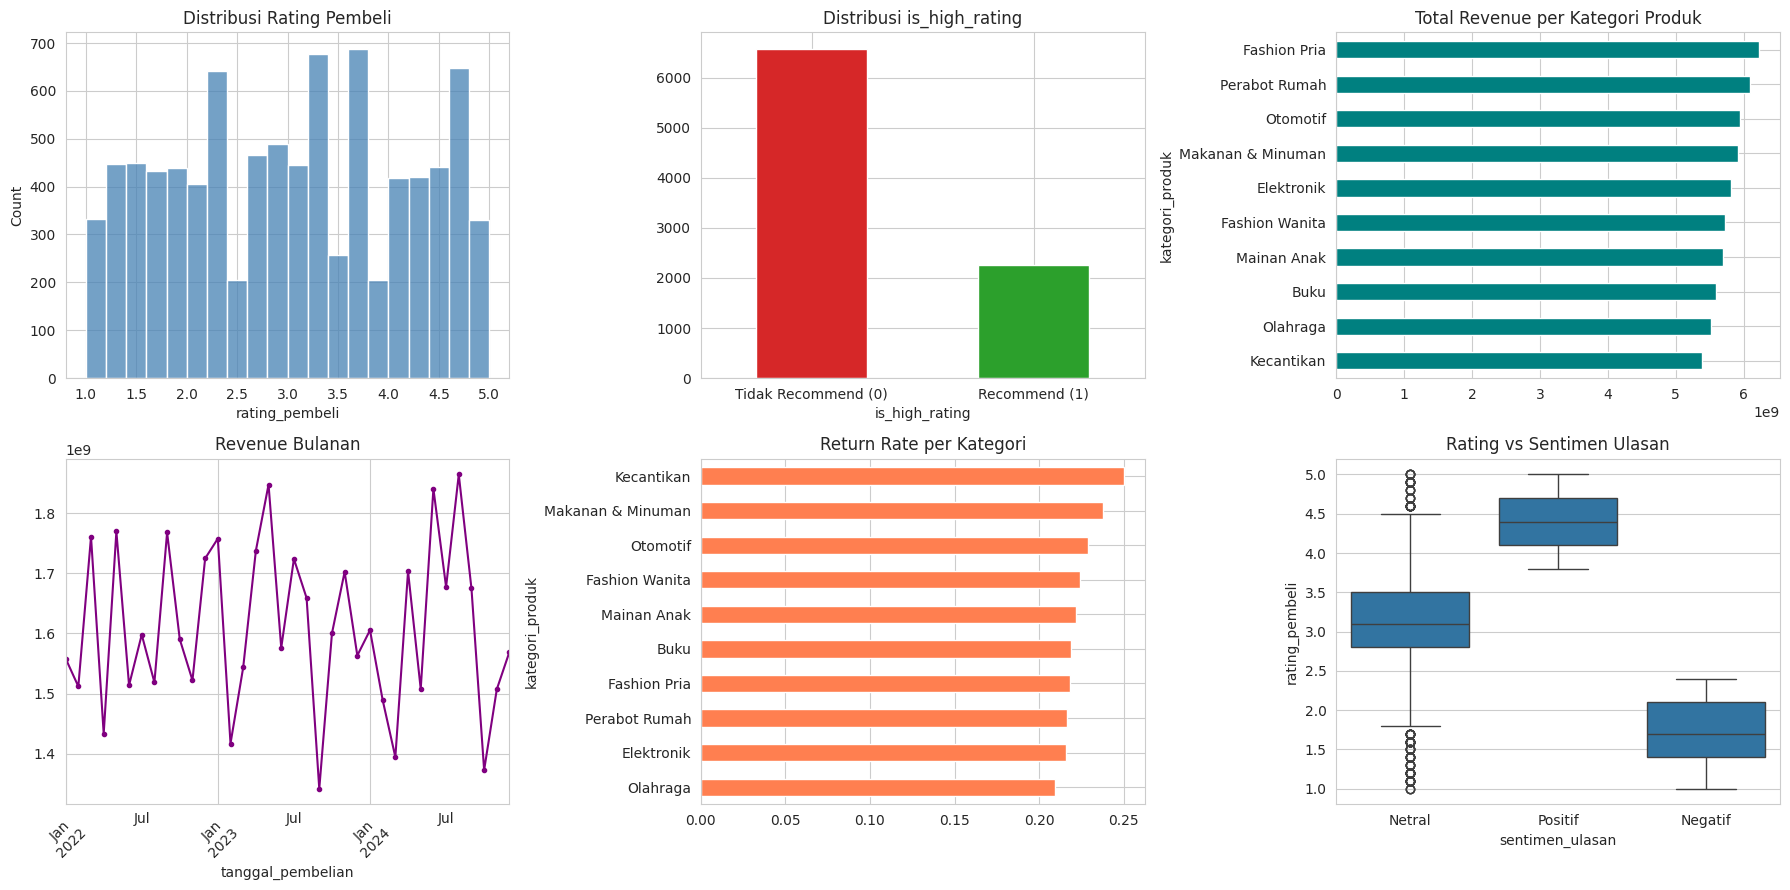

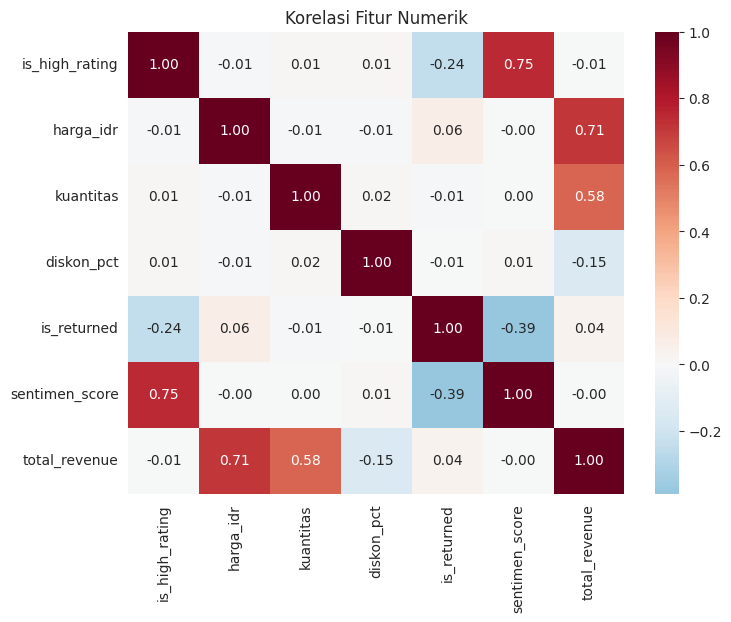

In [6]:
# ============================================================
# CELL 5 — EDA (Exploratory Data Analysis)
# ============================================================
fig, ax = plt.subplots(2, 3, figsize=(18, 9))

# 1. Distribusi rating
sns.histplot(d['rating_pembeli'].dropna(), bins=20, ax=ax[0,0], color='steelblue')
ax[0,0].set_title('Distribusi Rating Pembeli')

# 2. Distribusi target
d['is_high_rating'].value_counts().plot(kind='bar', ax=ax[0,1], color=['#d62728','#2ca02c'])
ax[0,1].set_title('Distribusi is_high_rating')
ax[0,1].set_xticklabels(['Tidak Recommend (0)','Recommend (1)'], rotation=0)

# 3. Revenue per kategori
d.groupby('kategori_produk')['total_revenue'].sum().sort_values().plot(
    kind='barh', ax=ax[0,2], color='teal')
ax[0,2].set_title('Total Revenue per Kategori Produk')

# 4. Revenue bulanan (time series)
monthly = d.dropna(subset=['tanggal_pembelian'])\
           .groupby(d['tanggal_pembelian'].dt.to_period('M'))['total_revenue'].sum()
monthly.plot(ax=ax[1,0], color='purple', marker='o', ms=3)
ax[1,0].set_title('Revenue Bulanan')
ax[1,0].tick_params(axis='x', rotation=45)

# 5. Return rate per kategori
rr = d.groupby('kategori_produk')['is_returned'].mean().sort_values()
rr.plot(kind='barh', ax=ax[1,1], color='coral')
ax[1,1].set_title('Return Rate per Kategori')

# 6. Sentimen vs rating
sns.boxplot(data=d.dropna(subset=['sentimen_ulasan','rating_pembeli']),
            x='sentimen_ulasan', y='rating_pembeli', ax=ax[1,2])
ax[1,2].set_title('Rating vs Sentimen Ulasan')

plt.tight_layout(); plt.show()

# Korelasi fitur numerik vs target
num_corr = d[['is_high_rating','harga_idr','kuantitas','diskon_pct',
              'is_returned','sentimen_score','total_revenue']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(num_corr, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Korelasi Fitur Numerik'); plt.show()

## Tahap 6: Analisis RFM (Segmentasi Pelanggan)

Analisis RFM (Recency, Frequency, Monetary) dilakukan untuk memahami perilaku pelanggan dan mengidentifikasi pelanggan VIP.
- **Recency**: Seberapa baru pelanggan melakukan transaksi.
- **Frequency**: Seberapa sering pelanggan bertransaksi.
- **Monetary**: Total uang yang dibelanjakan pelanggan.

*Catatan Penting:* Pelanggan dengan `user_id` "UNKNOWN" (hasil imputasi data kosong) **dikeluarkan** dari analisis ini agar tidak mencemari hasil segmentasi pelanggan asli.

In [7]:
# ============================================================
# TAMBAHAN: ANALISIS RFM (FIXED VERSION)
# ============================================================
# Pastikan tanggal sudah di-drop yang kosong untuk hitung Recency
rfm_data = d.dropna(subset=['tanggal_pembelian']).copy()

# Tanggal "hari ini" di dataset adalah tanggal transaksi terakhir
snapshot_date = rfm_data['tanggal_pembelian'].max() + pd.Timedelta(days=1)

# Hitung RFM per pelanggan
rfm = rfm_data.groupby('user_id').agg({
    'tanggal_pembelian': lambda x: (snapshot_date - x.max()).days, # Recency
    'transaction_id': 'count',                                     # Frequency
    'total_revenue': 'sum'                                         # Monetary
}).rename(columns={
    'tanggal_pembelian': 'Recency',
    'transaction_id': 'Frequency',
    'total_revenue': 'Monetary'
})

# 🔥 TAMBAHKAN 1 BARIS INI UNTUK MEMBUANG "UNKNOWN" 🔥
rfm = rfm[rfm.index != 'UNKNOWN']
# ---------------------------------------------------

print("=== CONTOH HASIL ANALISIS RFM (Top 5 Pelanggan) ===")
display(rfm.sort_values('Monetary', ascending=False).head())

# Simpan RFM
rfm.to_csv('analisis_rfm.csv')
print("\n✅ analisis_rfm.csv berhasil disimpan.")

=== CONTOH HASIL ANALISIS RFM (Top 5 Pelanggan) ===


,Recency,Frequency,Monetary
user_id,,,
USR00851,101,8,87408691.40
USR00807,418,6,75991219.65
USR02568,35,7,75661892.60
USR01923,86,10,74540985.20
USR00608,368,7,74165247.80



✅ analisis_rfm.csv berhasil disimpan.


## Tahap ini: Menyimpan Output (Data Bersih & Kamus Data)

Tahap terakhir dari proses Data Wrangling adalah menyimpan hasil kerja ke dalam file agar dapat digunakan di masa depan atau oleh tim lain.
Sesuai instruksi tugas:
1. **`data_bersih.csv`**: Dataset yang sudah melalui tahap pembersihan (tanpa missing value pada kolom kunci dan target).
2. **`kamus_data.csv`**: Metadata yang berisi daftar kolom, tipe data, jumlah *missing value*, dan jumlah nilai unik.

Kedua file ini disimpan ke dalam direktori `output/`.

In [8]:
# ============================================================
# TAMBAHAN: SIMPAN DATA BERSIH & KAMUS DATA
# ============================================================
import os
os.makedirs('output', exist_ok=True) # Membuat folder output jika belum ada

# 1. Simpan data bersih ke dalam folder output
df_clean.to_csv('output/data_bersih.csv', index=False)
print("✅ output/data_bersih.csv berhasil disimpan.")

# 2. Buat dan Simpan Kamus Data ke dalam folder output
kamus_data = pd.DataFrame({
    'Nama Kolom': df_clean.columns,
    'Tipe Data': df_clean.dtypes.astype(str).values,
    'Jumlah Missing': df_clean.isna().sum().values,
    'Jumlah Unik': df_clean.nunique().values
})
kamus_data.to_csv('output/kamus_data.csv', index=False)
print("✅ output/kamus_data.csv berhasil disimpan.")

print("\n=== ISI KAMUS DATA ===")
display(kamus_data)

✅ output/data_bersih.csv berhasil disimpan.
✅ output/kamus_data.csv berhasil disimpan.

=== ISI KAMUS DATA ===


,Nama Kolom,Tipe Data,Jumlah Missing,Jumlah Unik
0,transaction_id,object,0,8840
1,user_id,object,76,2845
2,product_id,object,0,500
3,kategori_produk,object,0,10
4,nama_produk,object,0,100
5,harga_idr,float64,0,8834
6,kuantitas,int64,0,5
7,diskon_pct,int64,0,7
8,rating_pembeli,float64,0,41
9,sentimen_ulasan,object,0,3


## Tahap 7: Pemodelan Klasifikasi (Anti-Data Leakage)

Tahap ini melatih model Machine Learning untuk memprediksi apakah pelanggan akan merekomendasikan produk (`is_high_rating`).
Langkah krusial yang dilakukan untuk mencegah *Data Leakage*:
1. **Split Terlebih Dahulu**: Data dibagi menjadi `train` (80%) dan `test` (20%) menggunakan `stratify=y` agar proporsi kelas tetap seimbang.
2. **Preprocessing di dalam Pipeline**: Proses imputasi, scaling (`StandardScaler`), dan encoding (`OneHotEncoder`) dimasukkan ke dalam `ColumnTransformer`. Proses `fit` hanya dilakukan pada data `X_train`, dan data `X_test` hanya di-`transform`.
3. **Model**: Menggunakan Logistic Regression dan Random Forest dengan parameter `class_weight='balanced'` untuk menangani data yang tidak seimbang.

Distribusi target : {0: 6581, 1: 2259} | Shape X : (8840, 12)

===== Logistic Regression =====
Accuracy : 0.4553
F1-score : 0.4581
ROC-AUC  : 0.6042
              precision    recall  f1-score   support

           0     0.8984    0.3024    0.4525      1316
           1     0.3072    0.9004    0.4581       452

    accuracy                         0.4553      1768
   macro avg     0.6028    0.6014    0.4553      1768
weighted avg     0.7473    0.4553    0.4539      1768


===== Random Forest =====
Accuracy : 0.5588
F1-score : 0.3935
ROC-AUC  : 0.6098
              precision    recall  f1-score   support

           0     0.7869    0.5585    0.6533      1316
           1     0.3034    0.5597    0.3935       452

    accuracy                         0.5588      1768
   macro avg     0.5451    0.5591    0.5234      1768
weighted avg     0.6633    0.5588    0.5869      1768



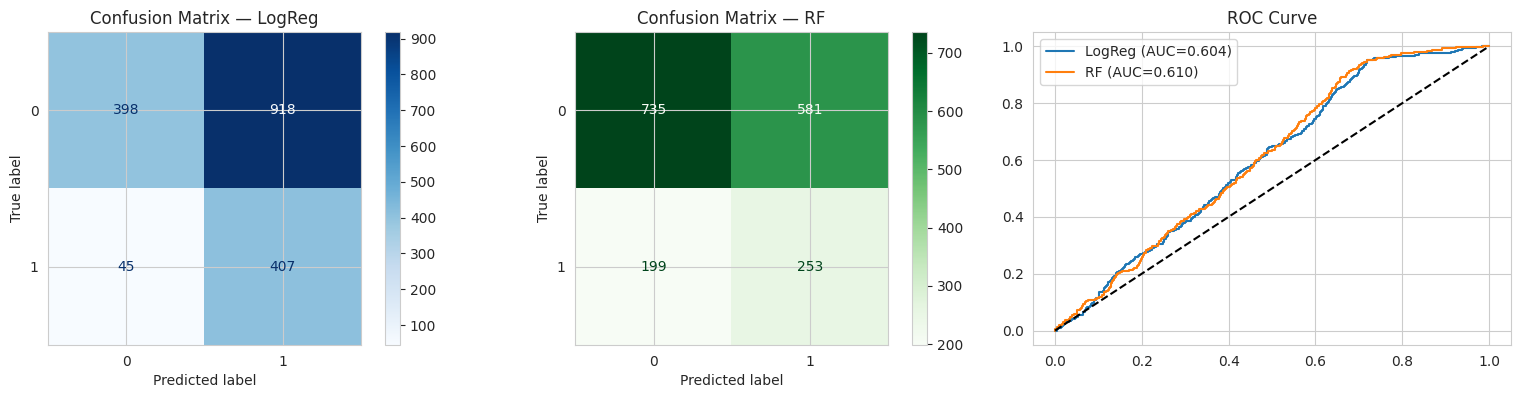

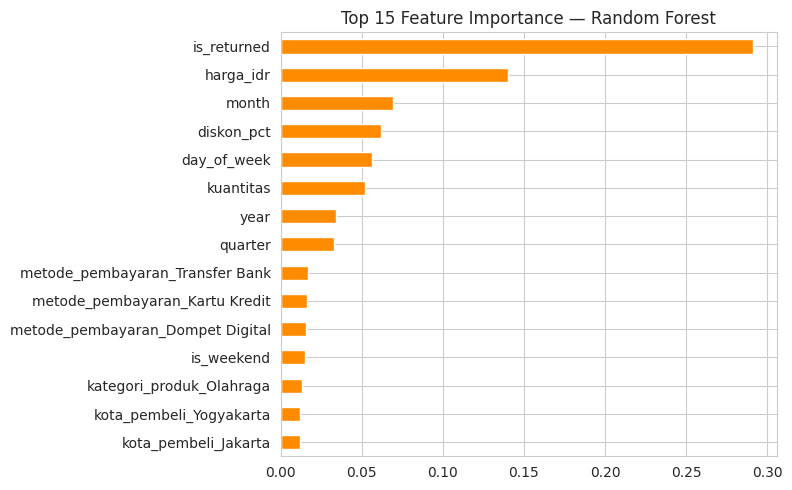

In [9]:
# ============================================================
# CELL 6 — Klasifikasi: "Akankah pelanggan merekomendasikan (rating>=4)?"
# ============================================================
# Data untuk klasifikasi = baris dengan target tidak NaN
cls = d.dropna(subset=['is_high_rating', 'tanggal_pembelian']).copy()
cls['is_high_rating'] = cls['is_high_rating'].astype(int)

# ⚠️ FITUR: jangan pakai rating_pembeli & sentimen_ulasan (LEAKAGE)
feature_num = ['harga_idr','kuantitas','diskon_pct','is_returned',
               'year','month','quarter','day_of_week','is_weekend']
feature_cat = ['kategori_produk','metode_pembayaran','kota_pembeli']

X = cls[feature_num + feature_cat]
y = cls['is_high_rating']
print('Distribusi target :', y.value_counts().to_dict(), '| Shape X :', X.shape)

# Split stratified
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Preprocessing: OHE untuk kategori, Scaling untuk numerik
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), feature_num),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), feature_cat)
])

# Model 1 — Logistic Regression
pipe_lr = Pipeline([('prep', preprocessor),
                    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))])
pipe_lr.fit(X_tr, y_tr)
y_pred_lr = pipe_lr.predict(X_te)
y_prob_lr = pipe_lr.predict_proba(X_te)[:,1]

# Model 2 — Random Forest
pipe_rf = Pipeline([('prep', preprocessor),
                    ('clf', RandomForestClassifier(n_estimators=300,
                                                    max_depth=10,
                                                    random_state=42,
                                                    class_weight='balanced'))])
pipe_rf.fit(X_tr, y_tr)
y_pred_rf = pipe_rf.predict(X_te)
y_prob_rf = pipe_rf.predict_proba(X_te)[:,1]

# === Evaluasi ===
def eval_model(name, y_true, y_pred, y_prob):
    print(f'\n===== {name} =====')
    print(f'Accuracy : {accuracy_score(y_true,y_pred):.4f}')
    print(f'F1-score : {f1_score(y_true,y_pred):.4f}')
    print(f'ROC-AUC  : {roc_auc_score(y_true,y_prob):.4f}')
    print(classification_report(y_true, y_pred, digits=4))

eval_model('Logistic Regression', y_te, y_pred_lr, y_prob_lr)
eval_model('Random Forest',       y_te, y_pred_rf, y_prob_rf)

# Confusion matrix + ROC curve
fig, ax = plt.subplots(1, 3, figsize=(16,4))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_lr, ax=ax[0], cmap='Blues')
ax[0].set_title('Confusion Matrix — LogReg')
ConfusionMatrixDisplay.from_predictions(y_te, y_pred_rf, ax=ax[1], cmap='Greens')
ax[1].set_title('Confusion Matrix — RF')

for name, prob in [('LogReg', y_prob_lr), ('RF', y_prob_rf)]:
    fpr, tpr, _ = roc_curve(y_te, prob)
    ax[2].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_te,prob):.3f})')
ax[2].plot([0,1],[0,1],'k--')
ax[2].set_title('ROC Curve'); ax[2].legend()
plt.tight_layout(); plt.show()

# Feature importance (Random Forest)
ohe_names = pipe_rf.named_steps['prep']\
             .named_transformers_['cat']\
             .get_feature_names_out(feature_cat)
all_feats = feature_num + list(ohe_names)
imp = pd.Series(pipe_rf.named_steps['clf'].feature_importances_,
                index=all_feats).sort_values(ascending=False).head(15)
plt.figure(figsize=(8,5))
imp.sort_values().plot(kind='barh', color='darkorange')
plt.title('Top 15 Feature Importance — Random Forest')
plt.tight_layout(); plt.show()

## Tahap 8: Clustering Produk (Segmentasi Produk)

Tahap ini menggunakan algoritma **K-Means Clustering** (Unsupervised Learning) untuk mengelompokkan produk berdasarkan karakteristiknya (harga, kuantitas, rating, return rate, dan revenue).
1. **Elbow & Silhouette Method**: Digunakan untuk menentukan jumlah cluster (k) yang optimal.
2. **Interpretasi Cluster**: Hasil cluster dianalisis untuk memberikan label bisnis, seperti "Star Product" (kualitas terbaik), "Volume Driver" (paling laris), dan "Bermasalah" (sering diretur). Ini sangat berguna untuk strategi rekomendasi produk dan alokasi stok.

Jumlah produk unik : 500
        avg_harga  avg_diskon  total_qty  total_revenue  avg_rating  return_rate  n_transaksi
count      500.00      500.00     500.00   5.000000e+02      500.00       500.00       500.00
mean   2502862.29       13.16      53.25   1.158953e+08        3.00         0.22        17.68
std     356451.08        2.78      13.48   3.576592e+07        0.28         0.10         4.05
min    1374235.09        5.00      19.00   2.468343e+07        2.16         0.00         7.00
25%    2283335.35       11.43      43.00   9.092044e+07        2.81         0.15        15.00
50%    2523504.17       12.97      52.00   1.128577e+08        2.99         0.21        18.00
75%    2743773.31       15.00      62.00   1.387892e+08        3.18         0.29        20.00
max    3504747.29       21.54      93.00   2.440067e+08        4.04         0.60        32.00


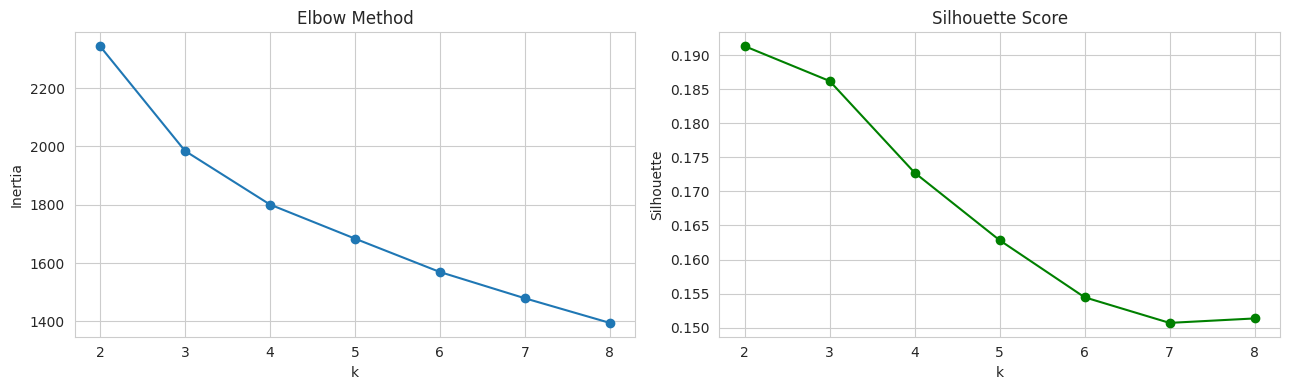


===== PROFIL CLUSTER (rata-rata) =====
          avg_harga  avg_diskon  total_qty  avg_rating  return_rate  total_revenue  n_transaksi
cluster                                                                                        
0        2677572.08       12.85      68.77        3.01         0.21   1.605005e+08        21.88
1        2572750.26       13.26      49.87        2.79         0.32   1.087586e+08        16.83
2        2543526.67       13.13      48.63        3.22         0.15   1.063606e+08        16.50
3        2030185.76       13.54      41.59        2.96         0.20   7.160796e+07        14.29

===== UKURAN TIAP CLUSTER =====
cluster
0    135
1    143
2    139
3     83
Name: count, dtype: int64


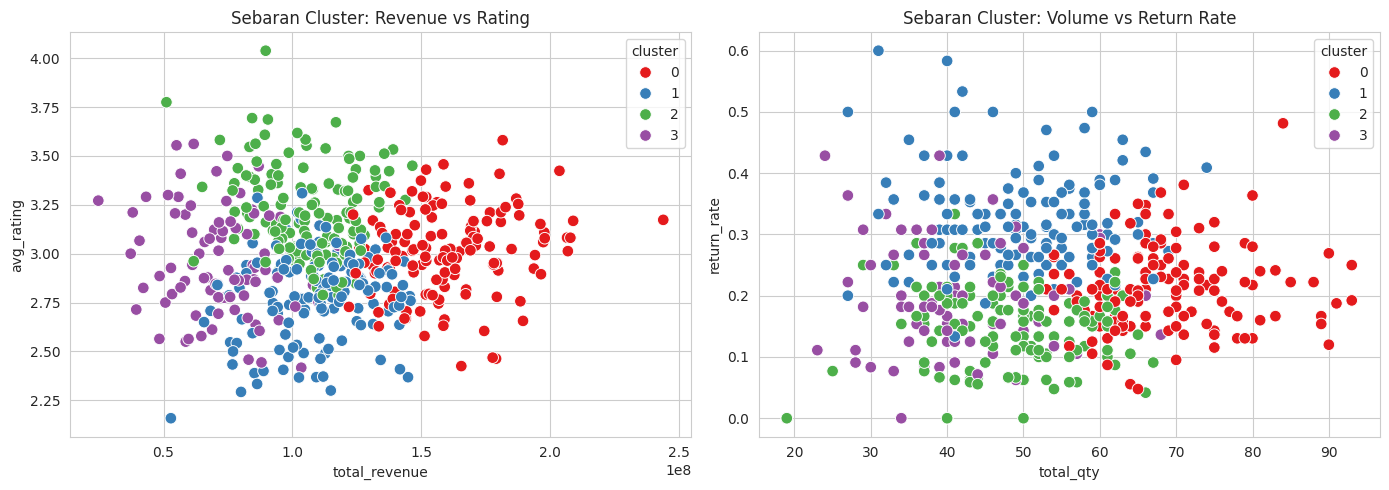


===== SEGMEN BISNIS =====
segmen
🔎 Niche / Perlu Eksplorasi        357
⚠️ Bermasalah (audit kualitas)    143
Name: count, dtype: int64

Contoh produk per segmen:
  🔎 Niche / Perlu Eksplorasi          -> ['PRD0001', 'PRD0005', 'PRD0008', 'PRD0010', 'PRD0011']
  ⚠️ Bermasalah (audit kualitas)      -> ['PRD0002', 'PRD0003', 'PRD0004', 'PRD0006', 'PRD0007']


In [10]:
# ============================================================
# CELL 7 — Clustering: Segmentasi Produk untuk Strategi Rekomendasi
# ============================================================
# Agregasi ke level produk
prod = d.groupby('product_id').agg(
    kategori        = ('kategori_produk','first'),
    avg_harga       = ('harga_idr','mean'),
    avg_diskon      = ('diskon_pct','mean'),
    total_qty       = ('kuantitas','sum'),
    total_revenue   = ('total_revenue','sum'),
    avg_rating      = ('rating_pembeli','mean'),
    return_rate     = ('is_returned','mean'),
    n_transaksi     = ('transaction_id','count')
).reset_index()

print('Jumlah produk unik :', len(prod))
print(prod.describe().round(2))

# Fitur untuk clustering
cluster_features = ['avg_harga','avg_diskon','total_qty',
                    'avg_rating','return_rate','total_revenue']
Xc = prod[cluster_features].fillna(prod[cluster_features].median())
Xc_scaled = StandardScaler().fit_transform(Xc)

# Elbow + Silhouette
inertia, sil = [], []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(Xc_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xc_scaled, lbl))

fig, ax = plt.subplots(1,2, figsize=(13,4))
ax[0].plot(list(K_range), inertia, marker='o'); ax[0].set_title('Elbow Method')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inertia')
ax[1].plot(list(K_range), sil, marker='o', color='green'); ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silhouette')
plt.tight_layout(); plt.show()

# Pilih k optimal (default k=4 untuk interpretasi bisnis yang jelas)
K_OPT = 4
km_final = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
prod['cluster'] = km_final.fit_predict(Xc_scaled)

# Interpretasi cluster
summary = prod.groupby('cluster')[cluster_features + ['n_transaksi']]\
              .mean().round(2)
print('\n===== PROFIL CLUSTER (rata-rata) =====')
print(summary)

print('\n===== UKURAN TIAP CLUSTER =====')
print(prod['cluster'].value_counts().sort_index())

# Visualisasi
fig, ax = plt.subplots(1,2, figsize=(14,5))
sns.scatterplot(data=prod, x='total_revenue', y='avg_rating',
                hue='cluster', palette='Set1', s=70, ax=ax[0])
ax[0].set_title('Sebaran Cluster: Revenue vs Rating')
sns.scatterplot(data=prod, x='total_qty', y='return_rate',
                hue='cluster', palette='Set1', s=70, ax=ax[1])
ax[1].set_title('Sebaran Cluster: Volume vs Return Rate')
plt.tight_layout(); plt.show()

# Beri nama bisnis ke tiap cluster (sesuaikan dg hasil summary)
label_map = {}  # isi manual setelah lihat summary di atas
for c in range(K_OPT):
    row = summary.loc[c]
    if row['avg_rating'] >= 4 and row['return_rate'] <= 0.2:
        label_map[c] = '⭐ Star Product (promosikan)'
    elif row['total_qty'] >= summary['total_qty'].median() and row['avg_harga'] < summary['avg_harga'].median():
        label_map[c] = '📦 Volume Driver (bundling)'
    elif row['return_rate'] > summary['return_rate'].median() + 0.05:
        label_map[c] = '⚠️ Bermasalah (audit kualitas)'
    else:
        label_map[c] = '🔎 Niche / Perlu Eksplorasi'

prod['segmen'] = prod['cluster'].map(label_map)
print('\n===== SEGMEN BISNIS =====')
print(prod['segmen'].value_counts())
print('\nContoh produk per segmen:')
for seg in prod['segmen'].unique():
    contoh = prod[prod['segmen']==seg]['product_id'].head(5).tolist()
    print(f'  {seg:35s} -> {contoh}')

In [11]:
# ============================================================
# CELL 8 — Auto-summary (bisa dipakai sebagai dasar laporan)
# ============================================================
print('='*60)
print('RINGKASAN AKHIR TUGAS — CASE 03 PRODUCT RECOMMENDATION')
print('='*60)
print(f'Transaksi awal         : {len(df):,}')
print(f'Setelah cleaning       : {len(d):,}')
print(f'Produk unik            : {d["product_id"].nunique():,}')
print(f'Pelanggan unik         : {d["user_id"].nunique():,}')
print(f'Missing value tersisa  : {int(d.isna().sum().sum())}')
print(f'\nRata-rata rating       : {d["rating_pembeli"].mean():.2f}')
print(f'Return rate keseluruhan: {d["is_returned"].mean()*100:.2f}%')
print(f'Total revenue          : Rp {d["total_revenue"].sum():,.0f}')
print(f'\nModel terbaik (F1)     : Random Forest  ({f1_score(y_te,y_pred_rf):.4f})')
print(f'Silhouette clustering  : {silhouette_score(Xc_scaled, prod["cluster"]):.4f}')
print('='*60)

RINGKASAN AKHIR TUGAS — CASE 03 PRODUCT RECOMMENDATION
Transaksi awal         : 10,000
Setelah cleaning       : 8,840
Produk unik            : 500
Pelanggan unik         : 2,845
Missing value tersisa  : 76

Rata-rata rating       : 3.00
Return rate keseluruhan: 22.40%
Total revenue          : Rp 57,947,631,229

Model terbaik (F1)     : Random Forest  (0.3935)
Silhouette clustering  : 0.1728


3 Temuan Utama & Rekomendasi Actionable
Berdasarkan hasil analisis data eksploratif (EDA), analisis RFM, dan pemodelan, terdapat tiga temuan krusial yang dapat ditindaklanjuti oleh manajemen:

1. Tingginya Tingkat Retur (Return Rate) pada Kategori Tertentu
Fakta Data: Tingkat pengembalian barang (retur) secara keseluruhan mencapai 22,46%. Berdasarkan grafik, kategori Kecantikan memiliki return rate tertinggi (mendekati 24%). Hal ini juga diperkuat oleh distribusi rating, di mana mayoritas pelanggan memberikan rating di bawah 4 (hanya ~24% yang merekomendasikan produk).

Dampak Bisnis: Tingginya retur mengurangi profitabilitas dan membebani biaya logistik balik, serta mengindikasikan ketidakpuasan pelanggan.

Rekomendasi Aksi: Lakukan audit kualitas produk secara menyeluruh pada kategori Kecantikan. Perbaiki deskripsi produk, foto, dan ekspektasi pengiriman agar tidak terjadi kesalahpahaman yang memicu retur.

2. Terdapat Segelintir Pelanggan VIP (Analisis RFM)
Fakta Data: Dari analisis RFM (Recency, Frequency, Monetary), ditemukan bahwa sebagian besar pelanggan hanya bertransaksi 1-2 kali, namun terdapat segelintir pelanggan (Top 5) yang menyumbang pendapatan (Monetary) sangat besar hingga ratusan juta rupiah.

Dampak Bisnis: Pelanggan VIP ini adalah aset berharga. Jika mereka berpindah ke kompetitor, pendapatan perusahaan akan turun drastis.

Rekomendasi Aksi: Terapkan strategi retensi khusus (seperti program Membership atau Loyalty Program). Berikan voucher eksklusif atau layanan prioritas bagi pelanggan dengan skor Monetary dan Frequency tertinggi.

3. Pola Musiman pada Pendapatan (Revenue)
Fakta Data: Grafik time series (Revenue Bulanan) menunjukkan pola fluktuatif dengan lonjakan penjualan yang jelas pada pertengahan tahun (sekitar kuartal 3) dan akhir tahun (kuartal 4).

Dampak Bisnis: Lonjakan ini bisa menjadi peluang emas jika diantisipasi, namun bisa menjadi masalah jika stok barang tidak siap.

Rekomendasi Aksi: Alihkan alokasi anggaran pemasaran (marketing budget) secara agresif pada bulan-bulan menjelang periode puncak tersebut. Pastikan juga manajemen rantai pasok (supply chain) menyiapkan stok produk Best Seller lebih awal.